## 1. 开始

形状为 [1, 512] 的 Tensor，表示图片经过神经网络编码后，被表示成了一个包含 512 个数值的特征向量，每一个数字通常没有可以直接解释的独立语义

import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

#模拟三张图片的特征
image_embeddings = torch.randn(3, 512)
print(image_embeddings.shape)

In [10]:
image_embeddings = torch.randn(3, 512)
text_embeddings = torch.randn(3, 768)
# similarity = image_embeddings @ text_embeddings.T  因为矩阵维度不匹配

## 2. 维度对齐与投影层

$Projection layer$在数学上就是一个线性变换,将不同维度的矩阵映射到同一维度$Y = xW + b$(其W权重为训练所得)

In [11]:
#模拟图像和文本输出
image_embeddings = torch.randn(3, 512)
text_embeddings = torch.randn(3, 768)

#创建投影层
image_projection = nn.Linear(512, 256)
text_projection = nn.Linear(768, 256)

#投影到共同空间
image_features = image_projection(image_embeddings)
text_features = text_projection(text_embeddings)

print(image_features.shape)
print(text_features.shape)

torch.Size([3, 256])
torch.Size([3, 256])


In [12]:
similarity = image_features @ text_features.T
print(similarity.shape)

torch.Size([3, 3])


维度相同只是能够计算相似度的数学条件；语义对齐才是CLIP真正要学习的东西

## 3. L2 归一化与余弦相似度

L2 归一化(原来的模长)$$\hat{v} = \frac{v}{|v|_2}$$


L2 范数展开(新模长)$$|v|_2 = \sqrt{\sum_{i=1}^{d} v_i^2}$$


余弦相似度$$\text{sim}(u, v) = \frac{u \cdot v}{|u|_2 |v|_2} = \cos\theta$$


相似度矩阵$$S = I_e T_e^T \in \mathbb{R}^{N \times N}$$

In [13]:
torch.manual_seed(42)

batch_size = 8
image_dim = 2048
text_dim = 768
embed_dim = 512

image_features = torch.randn(batch_size, image_dim)
text_features = torch.randn(batch_size, text_dim)

print(f"原始图像特征形状: {image_features.shape}")
print(f"原始文本特征形状: {text_features.shape}")

原始图像特征形状: torch.Size([8, 2048])
原始文本特征形状: torch.Size([8, 768])


向量的点积公式$$u \cdot v = \Vert{}u\Vert{}_2 \cdot \Vert{}v\Vert{}_2 \cdot \cos\theta$$

In [14]:
# 定义投影层
image_projection = nn.Linear(image_dim, embed_dim, bias=False)
text_projection = nn.Linear(text_dim, embed_dim, bias=False)

# 映射
image_emb = image_projection(image_features)
text_emb = text_projection(text_features)

# L2 归一化
image_emb = F.normalize(image_emb, p=2, dim=-1)
text_emb = F.normalize(text_emb, p=2, dim=-1)

# L2范数都等于1.0
print("图像向量模长:", torch.norm(image_emb, p=2, dim=-1))
print("文本向量模长:", torch.norm(text_emb, p=2, dim=-1))

图像向量模长: tensor([1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000],
       grad_fn=<LinalgVectorNormBackward0>)
文本向量模长: tensor([1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000],
       grad_fn=<LinalgVectorNormBackward0>)


In [15]:
# [N, 512] @ [512, N] -> [N, N]
similarity_matrix = image_emb @ text_emb.T

print(f"相似度矩阵形状: {similarity_matrix.shape}")
print("数值范围:", f"[{similarity_matrix.min():.3f}, {similarity_matrix.max():.3f}]")

相似度矩阵形状: torch.Size([8, 8])
数值范围: [-0.184, 0.152]


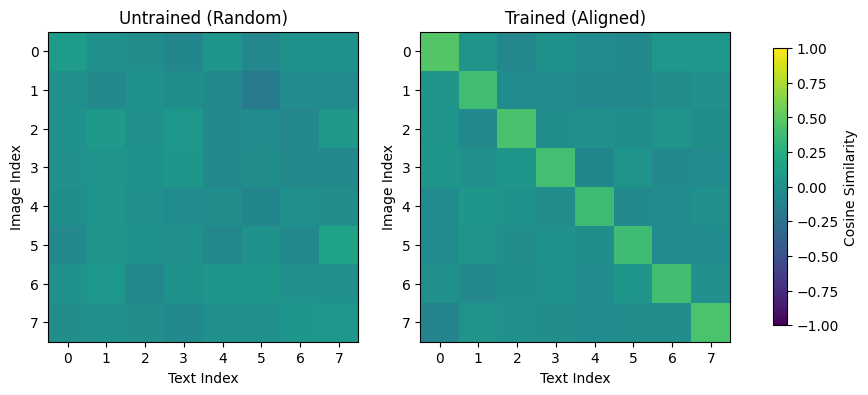

In [16]:
# 模拟训练后的理想状态：文本向量 = 图像向量 + 极小噪声，再做归一化
aligned_text_emb = F.normalize(image_emb + 0.1 * torch.randn_like(image_emb), p=2, dim=-1)
aligned_sim_matrix = image_emb @ aligned_text_emb.T

# 绘图对比
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

for ax, matrix, title in zip(
    axes,
    [similarity_matrix.detach().numpy(), aligned_sim_matrix.detach().numpy()],
    ["Untrained (Random)", "Trained (Aligned)"]
):
    im = ax.imshow(matrix, cmap="viridis", vmin=-1, vmax=1)
    ax.set_title(title)
    ax.set_xlabel("Text Index")
    ax.set_ylabel("Image Index")
    ax.set_xticks(range(batch_size))
    ax.set_yticks(range(batch_size))

fig.colorbar(im, ax=axes.ravel().tolist(), shrink=0.8, label="Cosine Similarity")
plt.show()